# BrainScan AI — Classification d'IRM cérébrale avec un CNN

**Objectif :** détecter et classifier les tumeurs cérébrales à partir d'images IRM en **4 classes** :
`glioma`, `meningioma`, `notumor`, `pituitary`.

Ce notebook est **auto-portant** (code natif, étape par étape) et couvre l'intégralité du cahier des charges :

| # | Étape | Sections du notebook |
|---|---|---|
| 1 | Chargement et prétraitement des données | cellules 1 → 13 |
| 2 | Conception du modèle CNN | cellules 14 → 18 |
| 3 | Entraînement et évaluation | cellules 19 → 27 |
| 4 | Déploiement et utilisation | cellules 28 → 31 |
| 5 | Documentation et bonnes pratiques | dernière cellule + `README.md` |

> **Artefacts produits :** `artifacts/models/` (modèle `.h5` + mapping des classes),
> `artifacts/figures/` (graphiques), `artifacts/metrics/` (métriques JSON).

## 1. Chargement et prétraitement des données

### 1.1 Imports des bibliothèques

OpenCV (redimensionnement), NumPy, TensorFlow/Keras, Matplotlib, Scikit-learn, etc. — le bruit des logs
TensorFlow est réduit et les **graines aléatoires** sont fixées pour la reproductibilité.

In [1]:
import os
import json
import time
import random
import warnings
from collections import Counter

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # réduire le bruit des logs TensorFlow
warnings.filterwarnings("ignore")

import numpy as np
import cv2  # OpenCV : lecture et redimensionnement des images
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, optimizers
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model, to_categorical
from tensorflow.keras.models import load_model

# Reproductibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU") or "non (entraînement CPU)")

I0000 00:00:1792319384.207837    6950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792319384.210798    6950 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792319386.240477    6950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792319386.242112    6950 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow : 2.21.0
GPU disponible : non (entraînement CPU)


E0000 00:00:1792319386.522583    6950 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


### Configuration du projet (chemins & hyperparamètres)

Les chemins sont résolus automatiquement quel que soit le répertoire de lancement
(racine du projet = dossier contenant `Dataset/`).

In [2]:
def find_project_root(start=os.getcwd()):
    '''Remonte l'arborescence jusqu'au dossier qui contient Dataset/ (racine du projet).'''
    path = os.path.abspath(start)
    while True:
        if os.path.isdir(os.path.join(path, "Dataset")) or os.path.isdir(os.path.join(path, "src")):
            return path
        parent = os.path.dirname(path)
        if parent == path:                       # racine du filesystem atteinte
            return os.path.abspath(os.path.join(start, ".."))
        path = parent

BASE_DIR = find_project_root()

# --- Arborescence ---
DATASET_DIR   = os.path.join(BASE_DIR, "Dataset")
RAW_DATA_DIR  = os.path.join(DATASET_DIR, "raw")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")
FIGURES_DIR   = os.path.join(ARTIFACTS_DIR, "figures")
METRICS_DIR   = os.path.join(ARTIFACTS_DIR, "metrics")
MODELS_DIR    = os.path.join(ARTIFACTS_DIR, "models")
for _d in (FIGURES_DIR, METRICS_DIR, MODELS_DIR):
    os.makedirs(_d, exist_ok=True)

BEST_MODEL_PATH  = os.path.join(MODELS_DIR, "brainscan_best_model.h5")  # checkpoint ModelCheckpoint
FINAL_MODEL_PATH = os.path.join(MODELS_DIR, "brainscan_model.h5")       # export du modèle final
MAPPING_PATH     = os.path.join(MODELS_DIR, "class_mapping.json")

# --- Extensions d'images valides (1.2) ---
VALID_EXTENSIONS = (".jpg", ".jpeg", ".bmp", ".png")

# --- Hyperparamètres, explicitement définis (2.5) ---
IMAGE_SIZE    = 224      # toutes les images sont redimensionnées en 224x224 (1.6)
BATCH_SIZE    = 32
EPOCHS        = 15
LEARNING_RATE = 1e-3
TEST_SIZE     = 0.20     # 20 % du dataset pour le test (1.12)
VAL_FRACTION  = 0.1875   # 15 % du dataset pour la validation (0.15 / 0.80 du reste)
RANDOM_STATE  = 42

print("Racine du projet :", BASE_DIR)
print(f"IMAGE_SIZE={IMAGE_SIZE} | BATCH_SIZE={BATCH_SIZE} | EPOCHS={EPOCHS} | "
      f"LEARNING_RATE={LEARNING_RATE} | TEST_SIZE={TEST_SIZE} | RANDOM_STATE={RANDOM_STATE}")

Racine du projet : /home/moali/projects/brainscan
IMAGE_SIZE=224 | BATCH_SIZE=32 | EPOCHS=15 | LEARNING_RATE=0.001 | TEST_SIZE=0.2 | RANDOM_STATE=42


### 1.4 Extraction des classes

Les **noms des dossiers** de `Dataset/raw/` servent de noms de classes (aucun codage en dur).

In [3]:
class_names = sorted(
    d for d in os.listdir(RAW_DATA_DIR)
    if os.path.isdir(os.path.join(RAW_DATA_DIR, d))
)

print(f"{len(class_names)} classes extraites des dossiers :")
for c in class_names:
    n = len(os.listdir(os.path.join(RAW_DATA_DIR, c)))
    print(f"  - {c:<12s} : {n} images")

4 classes extraites des dossiers :
  - glioma       : 1621 images
  - meningioma   : 1645 images
  - notumor      : 2000 images
  - pituitary    : 1757 images


### 1.2 → 1.6 Filtrage des extensions, gestion des erreurs, chargement

- **Filtrage (1.2)** : seules les extensions `.jpg`, `.jpeg`, `.bmp`, `.png` sont retenues,
  les autres fichiers sont **ignorés** et comptabilisés.
- **Gestion des erreurs (1.3)** : un bloc `try-except` par fichier capte les erreurs de lecture
  (fichier corrompu, tronqué…), le chargement se poursuit.
- **Listes synchronisées (1.5)** : les paires *(chemin, étiquette)* sont **mélangées aléatoirement**
  avant le chargement → deux listes distinctes (`images`, `labels`) avec **correspondance stricte des index**.
- **Redimensionnement (1.6)** : toutes les images sont redimensionnées à **224×224 via `cv2.resize`**
  et converties du format BGR d'OpenCV au format RGB.

In [4]:
def is_valid_extension(file_path):
    '''Vérifie (insensible à la casse) que le fichier a une extension d'image valide.'''
    return file_path.lower().endswith(VALID_EXTENSIONS)


def load_dataset(root_dir, image_size=IMAGE_SIZE):
    '''Charge le dataset : filtrage + try-except + mélange + cv2.resize.

    Retourne deux listes synchronisées (images, labels) et les statistiques
    des fichiers ignorés / en erreur.
    '''
    # Collecte des paires (chemin, classe) avec filtrage des extensions (1.2)
    pairs, ignored_extensions = [], []
    for class_name in class_names:
        class_dir = os.path.join(root_dir, class_name)
        for file_name in os.listdir(class_dir):
            file_path = os.path.join(class_dir, file_name)
            if not os.path.isfile(file_path):
                continue
            if not is_valid_extension(file_path):       # fichiers non conformes → ignorés
                ignored_extensions.append(file_path)
                continue
            pairs.append((file_path, class_name))

    # Mélange aléatoire en conservant la correspondance stricte des index (1.5)
    random.Random(RANDOM_STATE).shuffle(pairs)

    # Chargement avec gestion des erreurs (1.3) et redimensionnement fixe (1.6)
    images, labels, read_errors = [], [], []
    for file_path, class_name in pairs:
        try:
            img = cv2.imread(file_path, cv2.IMREAD_COLOR)
            if img is None:
                raise ValueError("cv2.imread a renvoyé None (fichier corrompu ?)")
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)       # BGR -> RGB
            img = cv2.resize(img, (image_size, image_size))  # taille fixe via OpenCV
            images.append(img)
            labels.append(class_name)
        except Exception as e:                                # gestion des erreurs de lecture
            read_errors.append((file_path, str(e)))

    return images, labels, ignored_extensions, read_errors


images, labels, ignored_extensions, read_errors = load_dataset(RAW_DATA_DIR)

print(f"Images chargées     : {len(images)}")
print(f"Extensions ignorées : {len(ignored_extensions)}")
print(f"Erreurs de lecture  : {len(read_errors)}")
for path, err in read_errors[:5]:
    print("   !", os.path.relpath(path, BASE_DIR), "->", err)

Images chargées     : 7023
Extensions ignorées : 0
Erreurs de lecture  : 0


### 1.7 Conversion en tableaux NumPy

Les deux listes sont converties en `np.array` (images en `uint8`, étiquettes en tableau de chaînes).

In [5]:
X = np.array(images, dtype=np.uint8)   # (N, 224, 224, 3) uint8
y_labels = np.array(labels)           # (N,) chaînes de caractères
del images, labels

print("X :", X.shape, X.dtype, "| min/max :", X.min(), X.max())
print("y :", y_labels.shape, y_labels.dtype)

X : (7023, 224, 224, 3) uint8 | min/max : 0 255
y : (7023,) <U10


### 1.8 Visualisation de la distribution des classes

Un **bar plot** affiche le nombre d'images présent pour chaque classe.

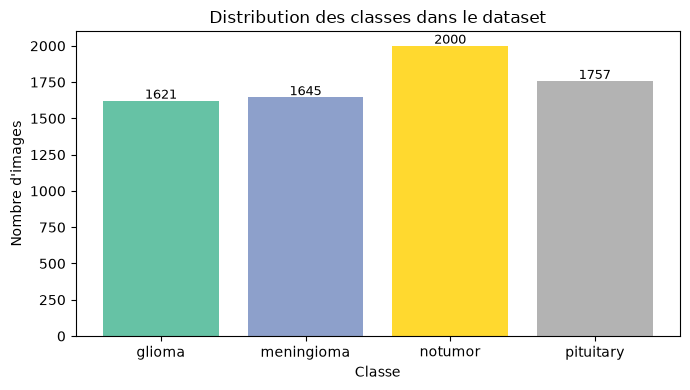

{'glioma': 1621, 'meningioma': 1645, 'notumor': 2000, 'pituitary': 1757}


In [6]:
counts = Counter(y_labels.tolist())

plt.figure(figsize=(7, 4))
colors = plt.cm.Set2(np.linspace(0, 1, len(class_names)))
bars = plt.bar(class_names, [counts[c] for c in class_names], color=colors)
plt.title("Distribution des classes dans le dataset")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 15,
             f"{int(bar.get_height())}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "class_distribution.png"), dpi=120)
plt.show()

print({c: counts[c] for c in class_names})

### 1.9 Échantillonnage visuel

**Au moins un exemple d'image pour chaque classe** du dataset (ici deux par classe).

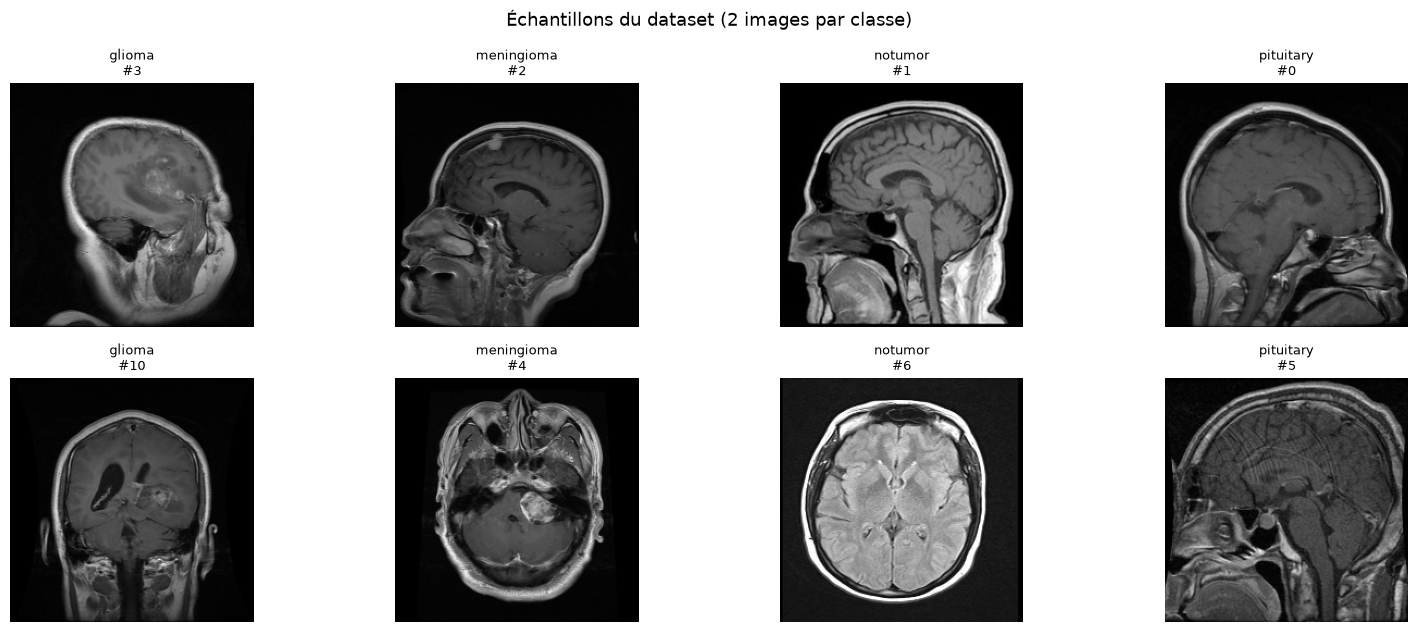

In [7]:
n_per_class = 2
fig, axes = plt.subplots(n_per_class, len(class_names), figsize=(4 * len(class_names), 3.2 * n_per_class))
for col, cls in enumerate(class_names):
    idxs = np.where(y_labels == cls)[0]
    for row in range(n_per_class):
        ax = axes[row, col]
        ax.imshow(X[idxs[row]])
        ax.set_title(f"{cls}\n#{idxs[row]}", fontsize=9)
        ax.axis("off")
fig.suptitle("Échantillons du dataset (2 images par classe)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "samples_per_class.png"), dpi=110)
plt.show()

### 1.10 Équilibrage des classes

**Constat :** l'équilibre est mesuré par le ratio max/min. Si un déséquilibre existe, une méthode de
rééquilibrage s'applique : ici les **poids de classe** (`class_weights`, calculés sur le sous-ensemble
d'entraînement et transmis à `model.fit`) — alternatives prévues : *oversampling* / *data augmentation*.
Les classes sont proches (ratio ≈ 1.23), les poids corrigeront donc faiblement mais réellement cet écart.

In [8]:
counts_arr = np.array([counts[c] for c in class_names])
ratio = counts_arr.max() / counts_arr.min()

print(f"Min = {counts_arr.min()} | Max = {counts_arr.max()} | Ratio max/min = {ratio:.2f}")
if ratio <= 1.5:
    print("-> Déséquilibre FAIBLE : rééquilibrage par class_weights (appliqué à l'entraînement, cf. section 3).")
else:
    print("-> Déséquilibre MARQUÉ : class_weights + oversampling/data augmentation à prévoir.")

Min = 1621 | Max = 2000 | Ratio max/min = 1.23
-> Déséquilibre FAIBLE : rééquilibrage par class_weights (appliqué à l'entraînement, cf. section 3).


### 1.11 Encodage des étiquettes

Conversion des étiquettes textuelles en valeurs numériques avec **`LabelEncoder`** (puis `to_categorical`
pour la cible *one-hot* utilisée par `categorical_crossentropy`). Le mapping est sauvegardé en JSON pour
le déploiement.

In [9]:
le = LabelEncoder()
y = le.fit_transform(y_labels)          # textuel -> numérique
class_names = list(le.classes_)         # ordre stable et explicite des classes
del y_labels

class_mapping = {cls: int(i) for i, cls in enumerate(class_names)}
with open(MAPPING_PATH, "w", encoding="utf-8") as f:
    json.dump(class_mapping, f, indent=2, ensure_ascii=False)

print("Mapping des classes :", class_mapping)
print("LabelEncoder classes_ :", class_names)
print("Distribution encodée :", dict(Counter(y.tolist())))

Mapping des classes : {np.str_('glioma'): 0, np.str_('meningioma'): 1, np.str_('notumor'): 2, np.str_('pituitary'): 3}
LabelEncoder classes_ : [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Distribution encodée : {3: 1757, 2: 2000, 1: 1645, 0: 1621}


### 1.12 Split Train / Validation / Test

Division **stratifiée** et proportionnelle avec `train_test_split` :
**68 % train / 12 % validation / 20 % test** (le test correspond à `TEST_SIZE = 0.20`,
la validation à 15 % du dataset total).

In [10]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=VAL_FRACTION, stratify=y_trainval, random_state=RANDOM_STATE)

del X, y, X_trainval, y_trainval

total = len(X_train) + len(X_val) + len(X_test)
for name, arr in [("Train", X_train), ("Validation", X_val), ("Test", X_test)]:
    print(f"{name:<12s}: {len(arr):5d} images ({100 * len(arr) / total:4.1f} %)  {arr.shape}")
assert len(X_train) == len(y_train) and len(X_val) == len(y_val) and len(X_test) == len(y_test)

Train       :  4564 images (65.0 %)  (4564, 224, 224, 3)
Validation  :  1054 images (15.0 %)  (1054, 224, 224, 3)
Test        :  1405 images (20.0 %)  (1405, 224, 224, 3)


### 1.13 Normalisation des pixels

Valeurs ramenées dans **[0, 1]** par division par `255.0`. Pour rester économe en mémoire (dataset de
7 000 images en 224×224), les tableaux sont conservés en `uint8` et la normalisation est appliquée
**par lot** dans le pipeline `tf.data` d'entraînement via la fonction `normalize()` ci-dessous —
**exactement** le même prétraitement que la fonction d'inférence (section 4). Les cibles sont converties
en *one-hot*.

In [11]:
def normalize(img_array):
    '''Normalisation [0, 1] : division par 255.0 (identiques entraînement / inférence).

    Gère les tableaux NumPy (inférence / démonstration) et les tenseurs tf.data (entraînement).
    '''
    if isinstance(img_array, np.ndarray):
        return img_array.astype("float32") / 255.0
    return tf.cast(img_array, tf.float32) / 255.0

# Démonstration de la normalisation sur un échantillon
sample_raw = X_train[:8]
sample_norm = normalize(sample_raw)
print("Avant normalisation : min =", sample_raw.min(), "| max =", sample_raw.max())
print("Après normalisation : min =", float(sample_norm.min()), "| max =", float(sample_norm.max()))

# Cibles one-hot
y_train_cat = to_categorical(y_train, num_classes=len(class_names))
y_val_cat   = to_categorical(y_val,   num_classes=len(class_names))
y_test_cat  = to_categorical(y_test,  num_classes=len(class_names))
print("y_train_cat :", y_train_cat.shape, y_train_cat.dtype)

Avant normalisation : min = 0 | max = 255
Après normalisation : min = 0.0 | max = 1.0
y_train_cat : (4564, 4) float64


---

## 2. Conception du modèle CNN

### 2.1 → 2.2 Architecture & activations

Architecture CNN « from scratch » : blocs **`Conv2D`** (ReLU) → **`MaxPooling2D`** → **`Dropout`**,
puis `GlobalAveragePooling2D`, couches **`Dense`** cachées (ReLU) et couche de sortie **`Dense(4, softmax)`**
(4 classes → softmax).

In [ ]:
def build_cnn(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3), num_classes=4):
    '''Construit le CNN : Conv2D + MaxPooling2D + Dropout + Dense (ReLU cachées, softmax sortie).'''
    model = keras.Sequential(name="brainscan_cnn")

    # Bloc 1 — extraction de traits bas niveau
    model.add(layers.Input(shape=input_shape))
    model.add(layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D(pool_size=2))
    model.add(layers.Dropout(0.25))

    # Bloc 2 — traits de niveau intermédiaire
    model.add(layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D(pool_size=2))
    model.add(layers.Dropout(0.25))

    # Bloc 3 — traits de haut niveau
    model.add(layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"))
    model.add(layers.MaxPooling2D(pool_size=2))
    model.add(layers.Dropout(0.25))

    # Classification
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(256, activation="relu"))   # couche cachée : ReLU
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation="softmax"))  # sortie : softmax (multi-classe)
    return model

model = build_cnn()

In [13]:
model.summary()

Model: "brainscan_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321,060 (1.22 MB)

 Trainable params: 321,060 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

### 2.4 Inspection du modèle : `model.summary()` (ci-dessus) et `plot_model()`

Si la binaire Graphviz n'est pas installée sur le système, un **équivalent** (schéma de l'architecture)
est généré avec Matplotlib et sauvegardé dans `artifacts/figures/`.

In [14]:
architecture_fig = os.path.join(FIGURES_DIR, "model_architecture.png")
try:
    plot_model(model, to_file=architecture_fig, show_shapes=True, show_layer_names=True, dpi=90)
    print("Schéma enregistré :", architecture_fig)
except Exception as e:
    print("plot_model indisponible (binaires graphviz absents) ->", e)
    print("Équivalent : schéma matplotlib de l'architecture\n")

    # ---- Équivalent de plot_model ----
    n_layers = len(model.layers)
    fig, ax = plt.subplots(figsize=(9, 0.55 * n_layers + 1.2))
    palette = {"Conv2D": "#4C72B0", "MaxPooling2D": "#55A868", "Dropout": "#C44E52",
               "Dense": "#8172B2", "GlobalAveragePooling2D": "#CCB974", "InputLayer": "#999999"}
    for i, layer in enumerate(model.layers):
        try:
            shape = tuple(layer.output.shape)[1:]
            shape_str = "x".join("?" if s is None else str(s) for s in shape)
        except Exception:
            shape_str = "?"
        color = palette.get(layer.__class__.__name__, "#CCCCCC")
        y0 = n_layers - i
        ax.add_patch(plt.Rectangle((0.05, y0 - 0.35), 0.9, 0.7, color=color, alpha=0.85))
        ax.text(0.5, y0, f"{i:>2d}  {layer.name}  [{layer.__class__.__name__}]  ->  {shape_str}",
                ha="center", va="center", fontsize=9, color="white", weight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, n_layers + 1); ax.axis("off")
    ax.set_title("Architecture du modèle (équivalent plot_model)", fontsize=11)
    plt.tight_layout()
    plt.savefig(architecture_fig, dpi=120, bbox_inches="tight")
    plt.show()
    print("Schéma enregistré :", architecture_fig)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.
Schéma enregistré : /home/moali/projects/brainscan/artifacts/figures/model_architecture.png


### 2.3 Compilation

Optimiseur **Adam** (taux d'apprentissage explicite), fonction de perte **`categorical_crossentropy`**
(cibles *one-hot*), métrique **accuracy**.

In [15]:
model.compile(
    optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
print(f"Optimiseur      : Adam (lr={LEARNING_RATE})")
print("Fonction de perte : categorical_crossentropy")
print("Métriques        : accuracy")

Optimiseur      : Adam (lr=0.001)
Fonction de perte : categorical_crossentropy
Métriques        : accuracy


---

## 3. Entraînement et Évaluation

### 3.1 → 3.2 Entraînement avec validation, sauvegarde du meilleur modèle, mesure du temps

- `model.fit(...)` configuré avec **train + validation** ;
- callback **`ModelCheckpoint`** → sauvegarde automatique des meilleurs poids
  (`artifacts/models/brainscan_best_model.h5`) ;
- `EarlyStopping` + `ReduceLROnPlateau` pour éviter le surapprentissage ;
- **1.10 (application)** : les **poids de classe** calculés sur le train sont transmis à l'entraînement ;
- **2.6** : le module **`time`** chronomètre la durée totale de l'entraînement.

In [16]:
# 1.10 — rééquilibrage : poids de classe calculés sur le sous-ensemble d'entraînement
cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train)
class_weights = {int(i): float(w) for i, w in enumerate(cw)}
print("Poids de classe :", {class_names[k]: round(v, 3) for k, v in class_weights.items()})

# Pipeline tf.data : normalisation par lot (normalize) + batching + prefetch
def make_dataset(X, y, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(X), 2048), seed=SEED)
    ds = ds.map(lambda x, y_: (normalize(x), y_), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train_cat, BATCH_SIZE, shuffle=True)
val_ds   = make_dataset(X_val,   y_val_cat,   BATCH_SIZE)
test_ds  = make_dataset(X_test,  y_test_cat,  BATCH_SIZE)

# 3.2 — callbacks
callbacks = [
    ModelCheckpoint(BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1),
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

# 2.6 + 3.1 — chronométrage et entraînement (train + validation)
start_time = time.time()
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1,
)
training_time = time.time() - start_time
print(f"\nDurée totale de l'entraînement : {training_time:.1f} s ({training_time / 60:.1f} min)")
print(f"Époques réellement exécutées    : {len(history.history['loss'])} / {EPOCHS}")

Poids de classe : {np.str_('glioma'): 1.083, np.str_('meningioma'): 1.067, np.str_('notumor'): 0.878, np.str_('pituitary'): 1.0}
Epoch 1/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 912ms/step - accuracy: 0.3856 - loss: 1.2409
Epoch 1: val_loss improved from None to 1.21192, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 1: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 979ms/step - accuracy: 0.3856 - loss: 1.2409 - val_accuracy: 0.3824 - val_loss: 1.2119 - learning_rate: 0.0010
Epoch 2/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.4991 - loss: 1.0714
Epoch 2: val_loss improved from 1.21192 to 0.97987, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 2: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.4991 - loss: 1.0714 - val_accuracy: 0.5370 - val_loss: 0.9799 - learning_rate: 0.0010
Epoch 3/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 935ms/step - accuracy: 0.5627 - loss: 0.9859
Epoch 3: val_loss improved from 0.97987 to 0.85954, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 3: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.5627 - loss: 0.9859 - val_accuracy: 0.6082 - val_loss: 0.8595 - learning_rate: 0.0010
Epoch 4/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 938ms/step - accuracy: 0.6383 - loss: 0.8753
Epoch 4: val_loss improved from 0.85954 to 0.85871, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 4: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.6383 - loss: 0.8753 - val_accuracy: 0.6157 - val_loss: 0.8587 - learning_rate: 0.0010
Epoch 5/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 925ms/step - accuracy: 0.6794 - loss: 0.7798
Epoch 5: val_loss improved from 0.85871 to 0.68404, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5


...


Epoch 6: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 143s 1000ms/step - accuracy: 0.7294 - loss: 0.6713 - val_accuracy: 0.7476 - val_loss: 0.6268 - learning_rate: 0.0010
Epoch 7/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 927ms/step - accuracy: 0.7504 - loss: 0.6384
Epoch 7: val_loss did not improve from 0.62678
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 990ms/step - accuracy: 0.7504 - loss: 0.6384 - val_accuracy: 0.6850 - val_loss: 0.7164 - learning_rate: 0.0010
Epoch 8/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 931ms/step - accuracy: 0.7528 - loss: 0.6332
Epoch 8: val_loss did not improve from 0.62678

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
143/143 ━━━━━━━━━━━━━━━━━━━━ 143s 999ms/step - accuracy: 0.7528 - loss: 0.6332 - val_accuracy: 0.7543 - val_loss: 0.6327 - learning_rate: 0.0010
Epoch 9/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 930ms/step - accuracy: 0.7840 - loss: 0.5568
Epoch 9: val_loss impr


Epoch 9: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 143s 1000ms/step - accuracy: 0.7840 - loss: 0.5568 - val_accuracy: 0.7932 - val_loss: 0.5326 - learning_rate: 5.0000e-04
Epoch 10/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 933ms/step - accuracy: 0.7800 - loss: 0.5565
Epoch 10: val_loss did not improve from 0.53263
143/143 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.7800 - loss: 0.5565 - val_accuracy: 0.7989 - val_loss: 0.5368 - learning_rate: 5.0000e-04
Epoch 11/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 926ms/step - accuracy: 0.7986 - loss: 0.5319
Epoch 11: val_loss did not improve from 0.53263

Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 993ms/step - accuracy: 0.7986 - loss: 0.5319 - val_accuracy: 0.7789 - val_loss: 0.5540 - learning_rate: 5.0000e-04
Epoch 12/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 930ms/step - accuracy: 0.8041 - loss: 0.5010
Epoch 1


Epoch 12: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 994ms/step - accuracy: 0.8041 - loss: 0.5010 - val_accuracy: 0.8188 - val_loss: 0.4702 - learning_rate: 2.5000e-04
Epoch 13/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 927ms/step - accuracy: 0.8173 - loss: 0.4803
Epoch 13: val_loss did not improve from 0.47024
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 991ms/step - accuracy: 0.8173 - loss: 0.4803 - val_accuracy: 0.8027 - val_loss: 0.5097 - learning_rate: 2.5000e-04
Epoch 14/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 938ms/step - accuracy: 0.8149 - loss: 0.4770
Epoch 14: val_loss improved from 0.47024 to 0.46055, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 14: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.8149 - loss: 0.4770 - val_accuracy: 0.8273 - val_loss: 0.4606 - learning_rate: 2.5000e-04
Epoch 15/15
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 927ms/step - accuracy: 0.8186 - loss: 0.4712
Epoch 15: val_loss improved from 0.46055 to 0.45561, saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5



Epoch 15: finished saving model to /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5
143/143 ━━━━━━━━━━━━━━━━━━━━ 142s 994ms/step - accuracy: 0.8186 - loss: 0.4712 - val_accuracy: 0.8330 - val_loss: 0.4556 - learning_rate: 2.5000e-04
Restoring model weights from the end of the best epoch: 15.

Durée totale de l'entraînement : 2142.0 s (35.7 min)
Époques réellement exécutées    : 15 / 15


### 3.3 Évaluation finale sur le sous-ensemble de test

`model.evaluate` mesure **loss** et **accuracy** sur le jeu de test (jamais vu pendant l'entraînement).
Les métriques sont aussi sauvegardées dans `artifacts/metrics/test_metrics.json`.

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f} ({test_accuracy * 100:.2f} %)")

# Prédictions sur le test (même pipeline de prétraitement que l'entraînement)
y_pred_proba = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)
y_true = np.argmax(y_test_cat, axis=1)

test_metrics = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs_trained": len(history.history["loss"]),
    "training_time_sec": round(training_time, 1),
    "classes": class_names,
}
with open(os.path.join(METRICS_DIR, "test_metrics.json"), "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2, ensure_ascii=False)
print("Métriques sauvegardées ->", os.path.join(METRICS_DIR, "test_metrics.json"))

44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 290ms/step - accuracy: 0.8335 - loss: 0.4627
Test loss     : 0.4627
Test accuracy : 0.8335 (83.35 %)
Métriques sauvegardées -> /home/moali/projects/brainscan/artifacts/metrics/test_metrics.json


### 3.4 Courbes d'apprentissage

Évolution de l'**accuracy** et de la **perte** pour l'entraînement **et** la validation.

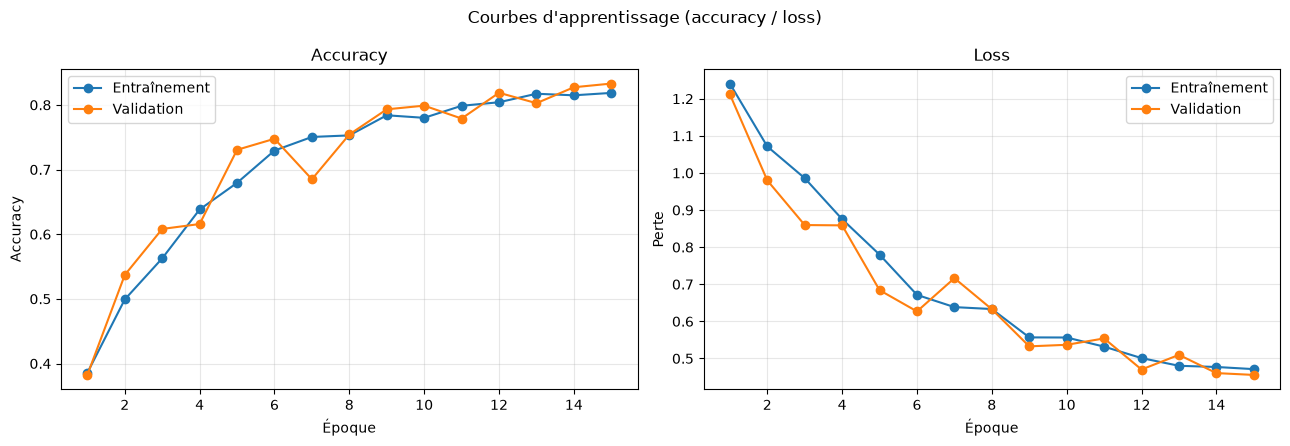

In [18]:
acc     = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss     = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs_range, acc, "o-", label="Entraînement")
axes[0].plot(epochs_range, val_acc, "o-", label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Accuracy")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, loss, "o-", label="Entraînement")
axes[1].plot(epochs_range, val_loss, "o-", label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Perte")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle("Courbes d'apprentissage (accuracy / loss)")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "learning_curves.png"), dpi=120)
plt.show()

### 3.5 Métriques avancées : matrice de confusion + rapport de classification

**Precision, Recall, F1-score** par classe et matrice de confusion annotée.

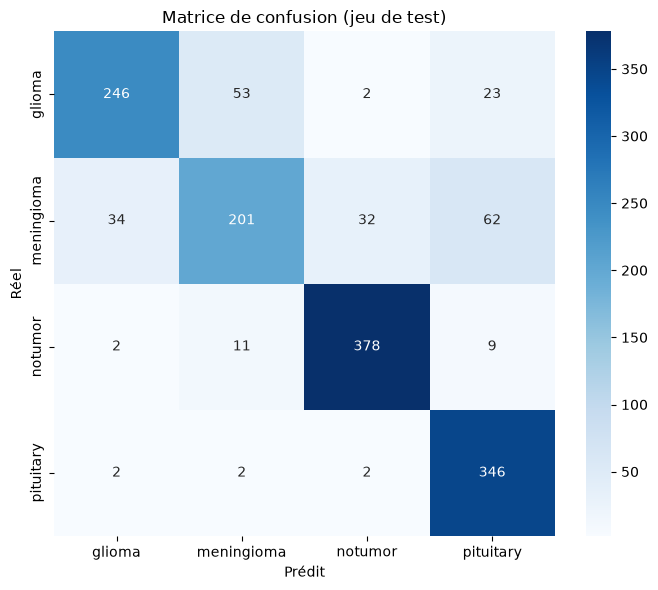

Rapport de classification :
              precision    recall  f1-score   support

      glioma      0.866     0.759     0.809       324
  meningioma      0.753     0.611     0.674       329
     notumor      0.913     0.945     0.929       400
   pituitary      0.786     0.983     0.874       352

    accuracy                          0.833      1405
   macro avg      0.830     0.825     0.822      1405
weighted avg      0.833     0.833     0.828      1405



In [19]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de confusion (jeu de test)")
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrix.png"), dpi=120)
plt.show()

report = classification_report(y_true, y_pred, target_names=class_names, digits=3)
print("Rapport de classification :")
print(report)

### 3.6 Analyse des prédictions : correctes vs incorrectes

Visualisation **côte à côte** d'exemples de bonnes prédictions (vert) et de prédictions erronées (rouge)
sur le jeu de test.

Prédictions correctes : 1171 | incorrectes : 234


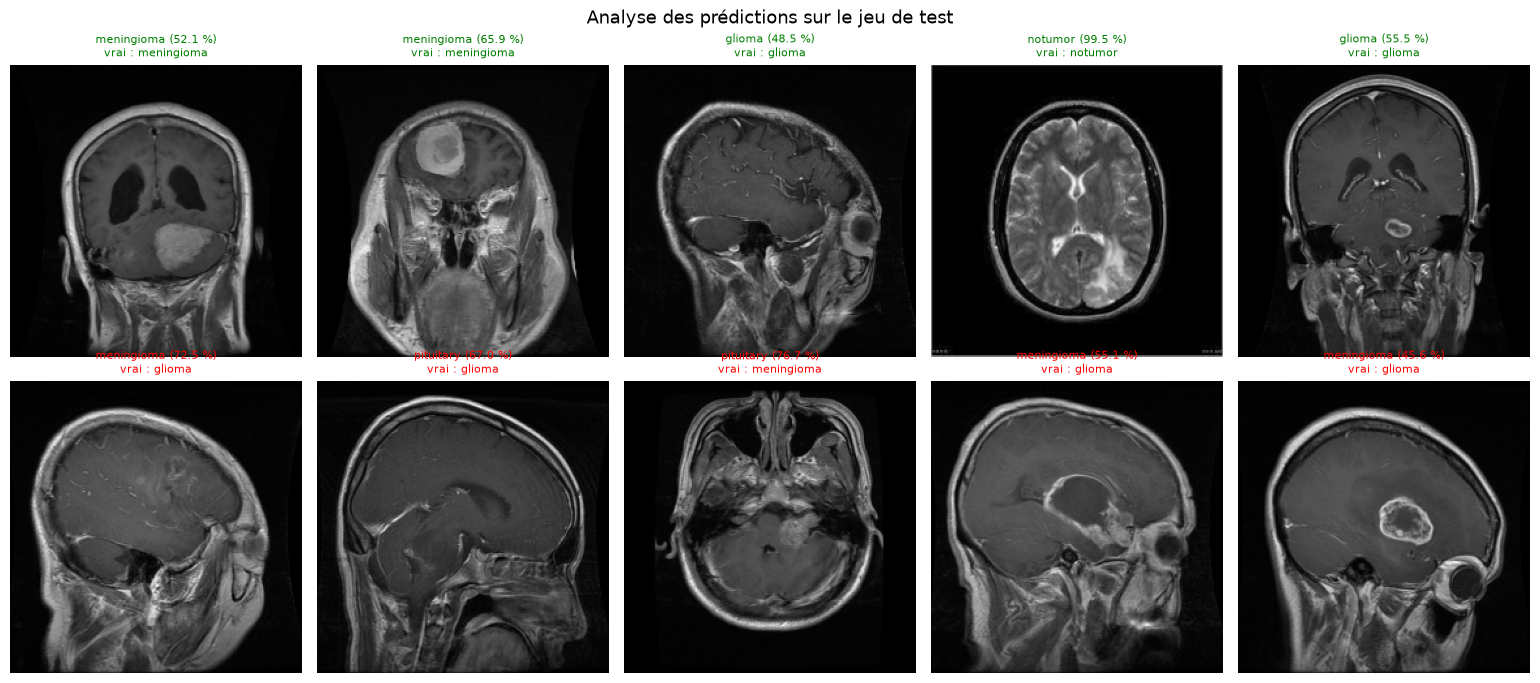

In [20]:
confidences = y_pred_proba[np.arange(len(y_pred)), y_pred]
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx   = np.where(y_pred != y_true)[0]
n = 5

fig, axes = plt.subplots(2, n, figsize=(3.1 * n, 7))
fig.suptitle("Analyse des prédictions sur le jeu de test", fontsize=13)

def show_row(ax_row, indices, title_prefix, color):
    for j in range(n):
        ax = ax_row[j]
        if j < len(indices):
            idx = indices[j]
            ax.imshow(X_test[idx])
            ax.set_title(f"{class_names[y_pred[idx]]} ({confidences[idx] * 100:.1f} %)\nvrai : {class_names[y_true[idx]]}",
                         fontsize=8, color=color)
        ax.axis("off")
    ax_row[0].set_ylabel(title_prefix, fontsize=11, color=color)

print(f"Prédictions correctes : {len(correct_idx)} | incorrectes : {len(wrong_idx)}")
show_row(axes[0], correct_idx[:n], "Correctes", "green")
if len(wrong_idx) == 0:
    print("Aucune prédiction incorrecte sur le jeu de test.")
else:
    show_row(axes[1], wrong_idx[:n], "Incorrectes", "red")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "predictions_analysis.png"), dpi=110)
plt.show()

---

## 4. Déploiement et Utilisation

### 4.2 Export du modèle

Le modèle final est sauvegardé au format standard **`.h5`** (HDF5), avec le mapping des classes
(`class_mapping.json`) qui accompagne le modèle pour l'inférence.

In [21]:
model.save(FINAL_MODEL_PATH)
size_mb = os.path.getsize(FINAL_MODEL_PATH) / 1e6
print(f"Modèle exporté    : {FINAL_MODEL_PATH} ({size_mb:.1f} MB)")
print(f"Checkpoint meilleur : {BEST_MODEL_PATH} "
      f"({'présent' if os.path.exists(BEST_MODEL_PATH) else 'absent'})")
print(f"Mapping classes     : {MAPPING_PATH}")

Modèle exporté    : /home/moali/projects/brainscan/artifacts/models/brainscan_model.h5 (3.9 MB)
Checkpoint meilleur : /home/moali/projects/brainscan/artifacts/models/brainscan_best_model.h5 (présent)
Mapping classes     : /home/moali/projects/brainscan/artifacts/models/class_mapping.json


### 4.1 Fonction d'inférence `predict_image(path)`

Prend le chemin d'une image, applique les **prétraitements exacts** de l'entraînement
(`cv2.imread` → BGR→RGB → `cv2.resize(224×224)` → `/255.0` → dimension *batch*) et **renvoie la prédiction**.
`detect_and_display` affiche le résultat (« No Tumor » ou la classe de tumeur + confiance), avec
gestion des erreurs via `try-except`.

In [22]:
_infer_model = None  # cache : le modèle n'est chargé qu'une fois

def _get_model():
    global _infer_model
    if _infer_model is None:
        _infer_model = load_model(FINAL_MODEL_PATH)
    return _infer_model

def predict_image(img_path, image_size=IMAGE_SIZE):
    '''4.1 — inférence : mêmes prétraitements que l'entraînement, renvoie un dict de prédiction.'''
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image introuvable ou illisible : {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (image_size, image_size))   # même taille qu'à l'entraînement
    arr = img.astype("float32") / 255.0               # même normalisation [0, 1]
    arr = np.expand_dims(arr, axis=0)                 # dimension batch

    probs = _get_model().predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    confidence = float(probs[idx])
    label = class_names[idx]

    return {
        "path": img_path,
        "class": label,
        "result": "No Tumor" if label == "notumor" else f"Tumor: {label}",
        "confidence": confidence,
        "probabilities": {class_names[i]: float(probs[i]) for i in range(len(class_names))},
    }


def detect_and_display(img_path, image_size=IMAGE_SIZE):
    '''Affiche l'image avec la prédiction (gestion des erreurs incluse).'''
    try:
        pred = predict_image(img_path, image_size=image_size)
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{pred['result']} (Confidence: {pred['confidence'] * 100:.2f}%)")
        plt.show()
        return pred
    except Exception as e:
        print("Error processing the image:", str(e))
        return None

### Démo : une prédiction par classe + gestion d'erreur

Le modèle est **rechargé depuis le fichier `.h5` exporté**, ce qui valide l'export.

--- glioma ---


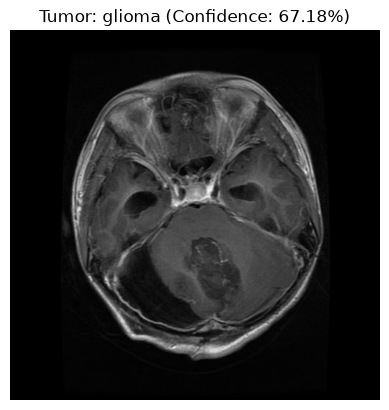

--- meningioma ---


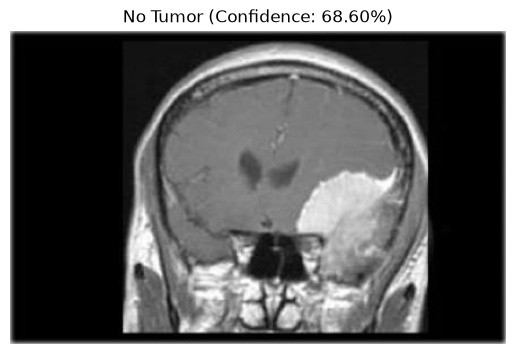

--- notumor ---


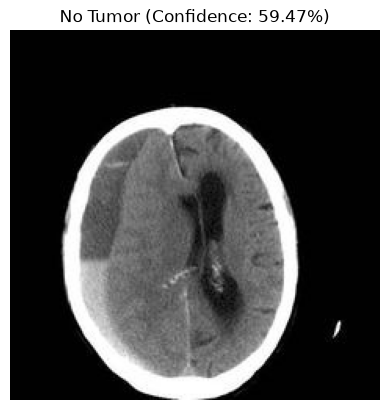

--- pituitary ---


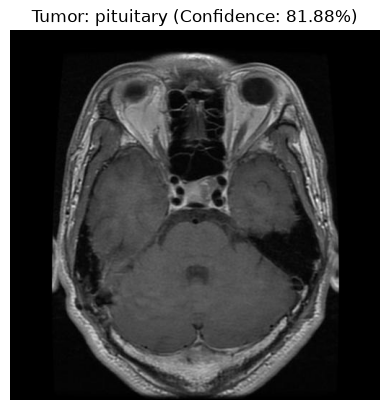

--- erreur simulée ---
Error processing the image: Image introuvable ou illisible : /home/moali/projects/brainscan/does_not_exist.png


[ WARN:0@2189.051] global loadsave.cpp:278 findDecoder imread_('/home/moali/projects/brainscan/does_not_exist.png'): can't open/read file: check file path/integrity


In [23]:
# Prédictions sur une image réelle de chaque classe
for cls in class_names:
    folder = os.path.join(RAW_DATA_DIR, cls)
    img_file = sorted(os.listdir(folder))[0]
    print(f"--- {cls} ---")
    detect_and_display(os.path.join(folder, img_file))

# Démonstration de la gestion des erreurs (chemin inexistant)
print("--- erreur simulée ---")
detect_and_display(os.path.join(BASE_DIR, "does_not_exist.png"))

In [24]:
# Résumé des probabilités pour une image
sample = predict_image(os.path.join(RAW_DATA_DIR, class_names[0], sorted(os.listdir(os.path.join(RAW_DATA_DIR, class_names[0])))[0]))
print("Résultat :", sample["result"], f"({sample['confidence'] * 100:.2f} %)")
for c, p in sample["probabilities"].items():
    print(f"   {c:<12s} : {p * 100:6.2f} %")

Résultat : Tumor: glioma (67.18 %)
   glioma       :  67.18 %
   meningioma   :  23.80 %
   notumor      :   0.63 %
   pituitary    :   8.39 %
